# Experiment 07: symmetric tensor transfer learning curves

Five training recipes at N = 10, 50, 100, 200 and 800 training structures, with one seed (42) each. The training sets are nested, and every run uses the same 50 validation and 150 test structures. Each model is its validation-selected checkpoint. Isotropic shielding σiso, Haeberlen anisotropy Δ and asymmetry η are extracted with Soprano from the reconstructed `0e + 2e` predictions and compared with the original DFT tensors. All atoms are retained, including opposite-sign anisotropy cases.

The N100 direct training, full fine-tuning and ELoRA points are Experiments 01, 05 and 06. Direct training, full fine-tuning and NMR-head-only at N800 hit the 12-hour limit before stopping and are not plotted; their folders are in `graph-pes-results/07-LearningCurves/incomplete/`.

**Balanced error** is ½(MSE_Si / var_Si + MSE_O / var_O) for each parameter, where each variance is that parameter's DFT variance over the full 800-structure training pool. It weights the two elements equally and uses no validation or test labels.

In [1]:
from pathlib import Path
import subprocess
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(ROOT))
from analysis_helpers.learning_curves import (load_curves, run_summary, rmse_table,
                                              plot_parameter_curves, save_figure)

DATA = ROOT / 'experiments/07-SymmetricTensor-LearningCurves-data'
FIGURES = DATA / 'figures'
# Re-run inference for any run without a cached prediction. Does not train.
RECOMPUTE = False
if RECOMPUTE:
    subprocess.run([sys.executable, str(ROOT / 'scripts/evaluate_experiment07.py'), '--allow-missing'],
                   check=True, cwd=ROOT)
curves, source = load_curves(ROOT, DATA)
pd.set_option('display.precision', 4)
print('Metrics from', source)

Metrics from metrics-partial.csv


## Runs

`Best epoch` is the validation-selected checkpoint. `Last epoch` is where early stopping (300 epochs without improvement) ended the run. The reused N100 runs from Experiments 01, 05 and 06 have no Experiment 07 audit record, so their epochs are blank.

In [2]:
display(run_summary(ROOT, DATA))

,Method,N,Run,Best epoch,Last epoch
0,Full fine-tuning,10,07-SymmetricTensor-full-N10-9457374,563.0,863.0
1,Full fine-tuning,50,07-SymmetricTensor-full-N50-9457512,346.0,646.0
2,Full fine-tuning,100,05-SymmetricTensor-FullFineTune-N100-9274115,NaN,NaN
3,Full fine-tuning,200,07-SymmetricTensor-full-N200-9457613,227.0,527.0
4,Full fine-tuning,800,missing (did not finish),NaN,NaN
5,ELoRA,10,07-SymmetricTensor-elora-N10-9460884,294.0,594.0
6,ELoRA,50,07-SymmetricTensor-elora-N50-9462819,232.0,532.0
7,ELoRA,100,06-SymmetricTensor-ELoRA-N100-R4-9274116,NaN,NaN
8,ELoRA,200,07-SymmetricTensor-elora-N200-9464322,364.0,664.0
9,ELoRA,800,07-SymmetricTensor-elora-N800-9464937,219.0,519.0


## Isotropic shielding σiso

Test RMSE in ppm for Si and O, and the element-balanced standardised MSE. Both axes are logarithmic.

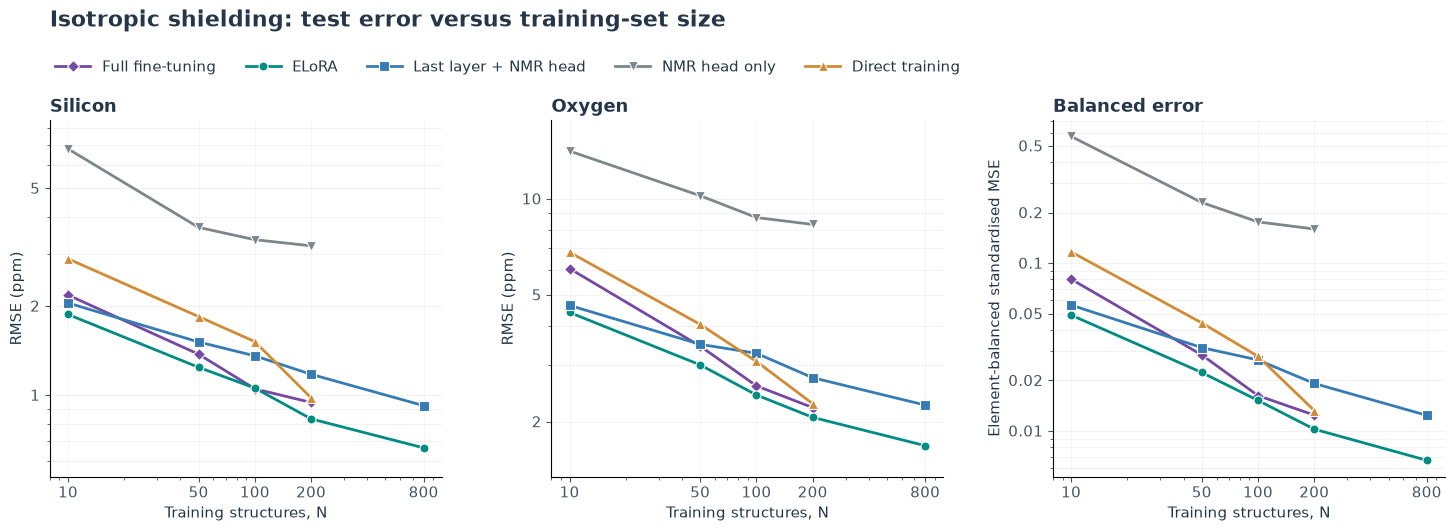

N                                   10       50      100     200     800
Element  Method                                                         
Si       Full fine-tuning        2.1786   1.3745  1.0501  0.9443     NaN
         ELoRA                   1.8734   1.2416  1.0562  0.8312  0.6634
         Last layer + NMR head   2.0480   1.5118  1.3575  1.1758  0.9214
         NMR head only           6.7929   3.6870  3.3504  3.1946     NaN
         Direct training         2.8888   1.8421  1.5163  0.9787     NaN
O        Full fine-tuning        6.0433   3.4510  2.5901  2.2138     NaN
         ELoRA                   4.4014   3.0136  2.4252  2.0628  1.6814
         Last layer + NMR head   4.6308   3.4961  3.2760  2.7469  2.2540
         NMR head only          14.1174  10.2260  8.7347  8.3086     NaN
         Direct training         6.7979   4.0362  3.0895  2.2770     NaN
balanced Full fine-tuning        0.0803   0.0284  0.0162  0.0124     NaN
         ELoRA                   0.0490   0.0223  0.0152  0.0102  0.0067
         Last layer + NMR head   0.0562   0.0314  0.0265  0.0192  0.0124
         NMR head only           0.5690   0.2298  0.1762  0.1597     NaN
         Direct training         0.1167   0.0441  0.0278  0.0132     NaN

In [3]:
fig = plot_parameter_curves(curves, 'isotropy', 'test')
save_figure(fig, FIGURES, 'test-isotropy-learning-curves')
plt.show()
display(rmse_table(curves, 'isotropy', 'test'))

## Shielding anisotropy Δ

Test RMSE in ppm for Si and O, and the element-balanced standardised MSE. Both axes are logarithmic.

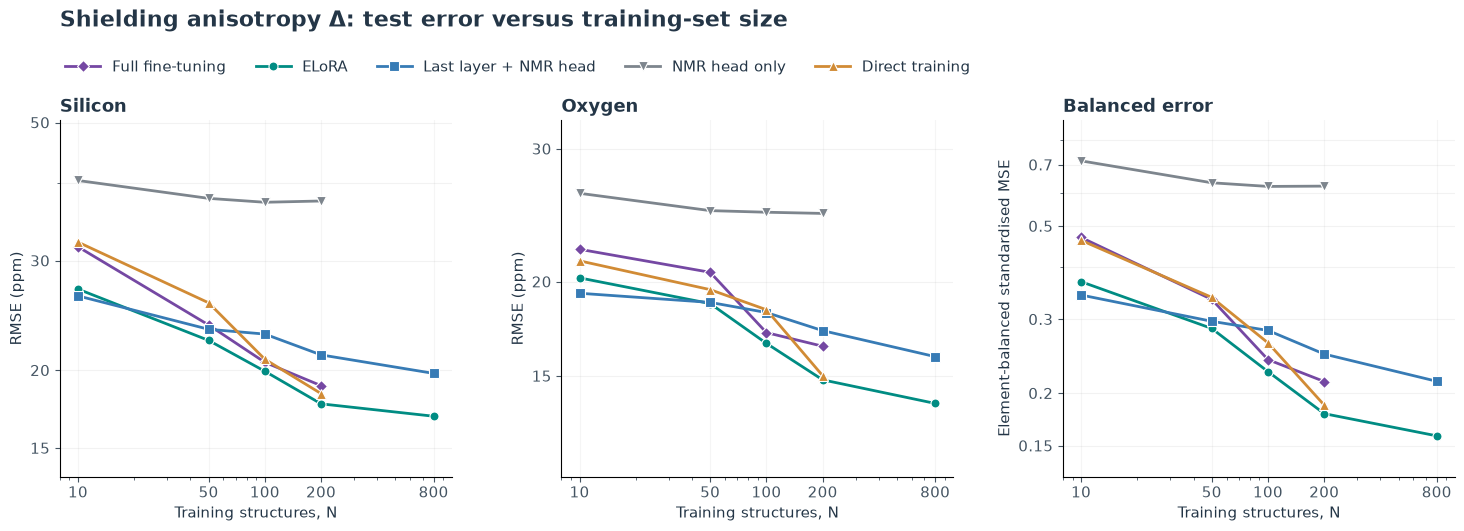

N                                   10       50       100      200      800
Element  Method                                                            
Si       Full fine-tuning       31.5936  23.6592  20.6055  18.9017      NaN
         ELoRA                  27.0168  22.3472  19.9357  17.6724  16.8804
         Last layer + NMR head  26.3460  23.2842  22.8743  21.1801  19.7790
         NMR head only          40.3739  37.7900  37.2482  37.4250      NaN
         Direct training        32.1436  25.6815  20.8414  18.3542      NaN
O        Full fine-tuning       22.0861  20.5865  17.1278  16.4293      NaN
         ELoRA                  20.2417  18.7139  16.5746  14.8288  13.7988
         Last layer + NMR head  19.3134  18.7813  18.2104  17.2310  15.9167
         NMR head only          26.2007  24.8510  24.7293  24.6391      NaN
         Direct training        21.3209  19.5264  18.3651  15.0179      NaN
balanced Full fine-tuning        0.4701   0.3348   0.2406   0.2134      NaN
         ELoRA                   0.3689   0.2855   0.2253   0.1789   0.1584
         Last layer + NMR head   0.3429   0.2969   0.2824   0.2481   0.2137
         NMR head only           0.7155   0.6345   0.6219   0.6229      NaN
         Direct training         0.4627   0.3385   0.2638   0.1875      NaN

In [4]:
fig = plot_parameter_curves(curves, 'anisotropy', 'test')
save_figure(fig, FIGURES, 'test-anisotropy-learning-curves')
plt.show()
display(rmse_table(curves, 'anisotropy', 'test'))

## Asymmetry η

Test RMSE in dimensionless for Si and O, and the element-balanced standardised MSE. Both axes are logarithmic.

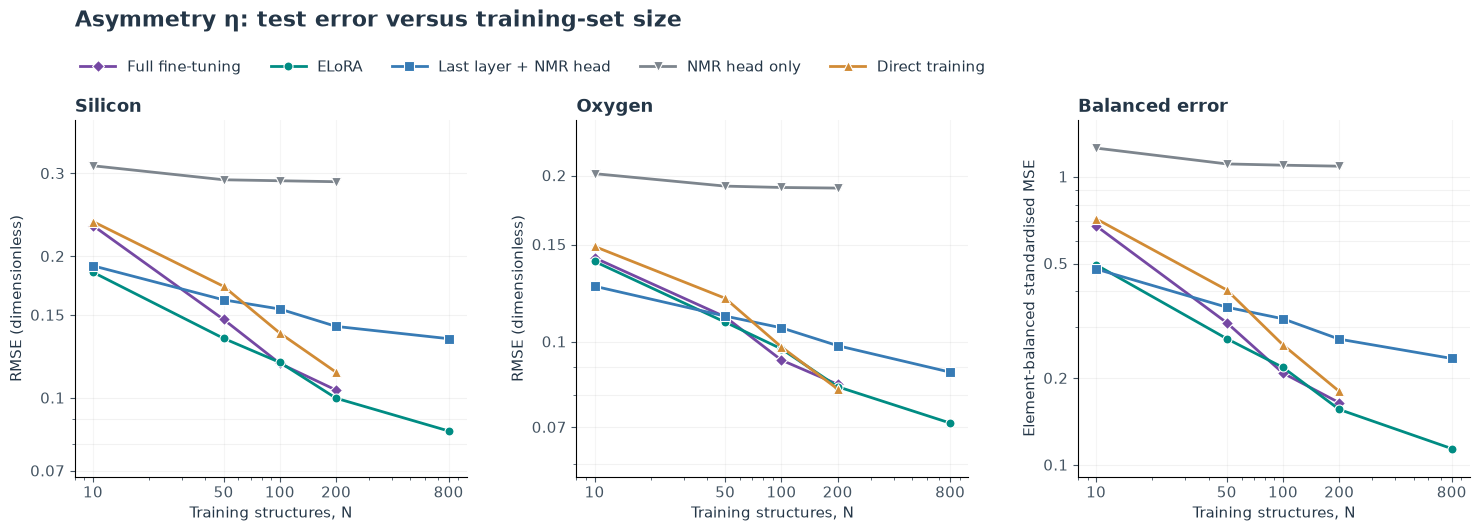

N                                  10      50      100     200     800
Element  Method                                                       
Si       Full fine-tuning       0.2324  0.1468  0.1184  0.1039     NaN
         ELoRA                  0.1850  0.1338  0.1190  0.0999  0.0851
         Last layer + NMR head  0.1909  0.1616  0.1545  0.1419  0.1336
         NMR head only          0.3115  0.2909  0.2895  0.2881     NaN
         Direct training        0.2371  0.1726  0.1374  0.1134     NaN
O        Full fine-tuning       0.1419  0.1109  0.0926  0.0837     NaN
         ELoRA                  0.1398  0.1085  0.0971  0.0829  0.0712
         Last layer + NMR head  0.1261  0.1113  0.1060  0.0984  0.0881
         NMR head only          0.2016  0.1914  0.1903  0.1898     NaN
         Direct training        0.1488  0.1199  0.0978  0.0821     NaN
balanced Full fine-tuning       0.6757  0.3117  0.2083  0.1644     NaN
         ELoRA                  0.4949  0.2743  0.2179  0.1558  0.1139
         Last layer + NMR head  0.4786  0.3528  0.3216  0.2733  0.2342
         NMR head only          1.2578  1.1083  1.0971  1.0884     NaN
         Direct training        0.7148  0.4049  0.2610  0.1800     NaN

In [5]:
fig = plot_parameter_curves(curves, 'asymmetry', 'test')
save_figure(fig, FIGURES, 'test-asymmetry-learning-curves')
plt.show()
display(rmse_table(curves, 'asymmetry', 'test'))

## Validation curves

The validation set chose the checkpoints, so these curves are not independent of model selection. They are shown to check that the test trends are consistent.

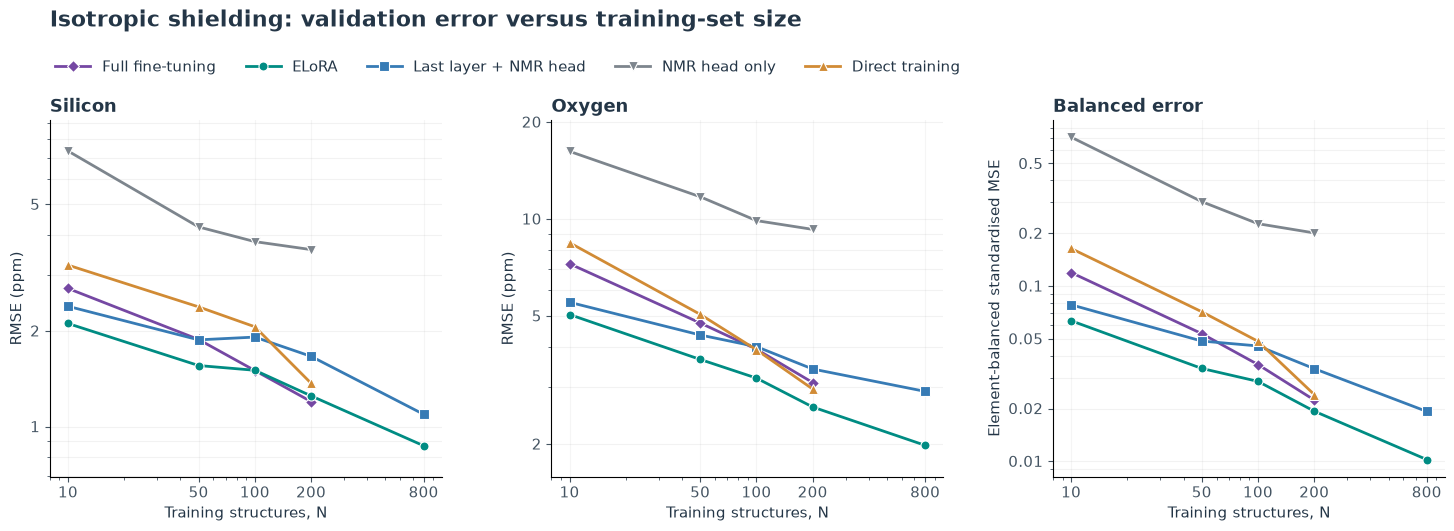

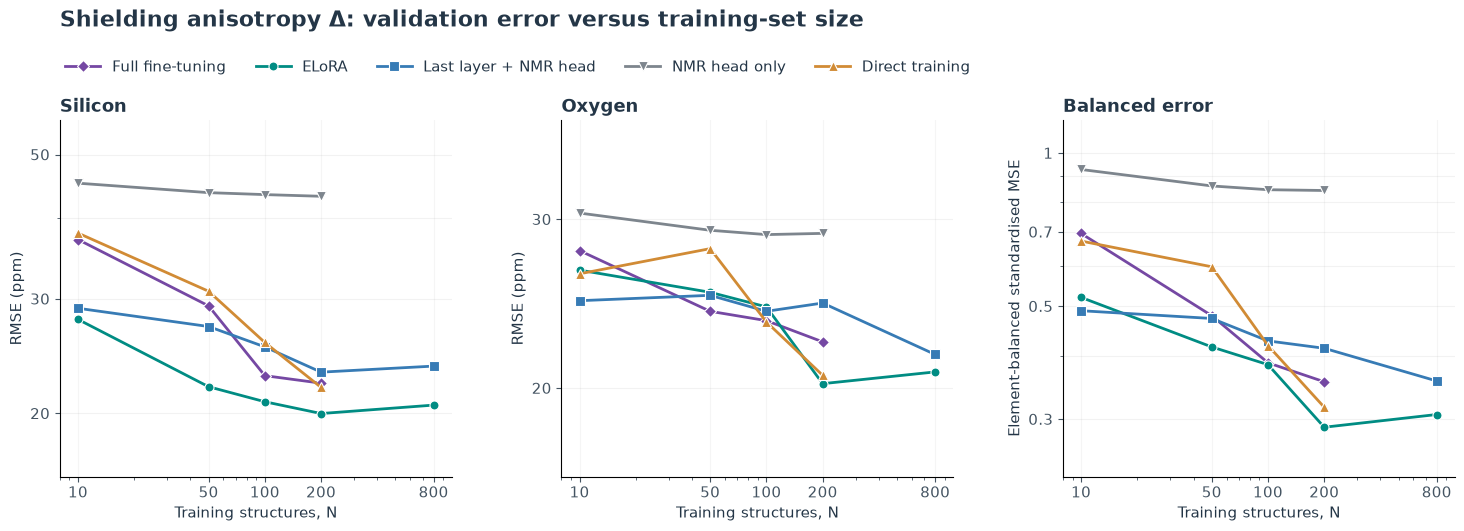

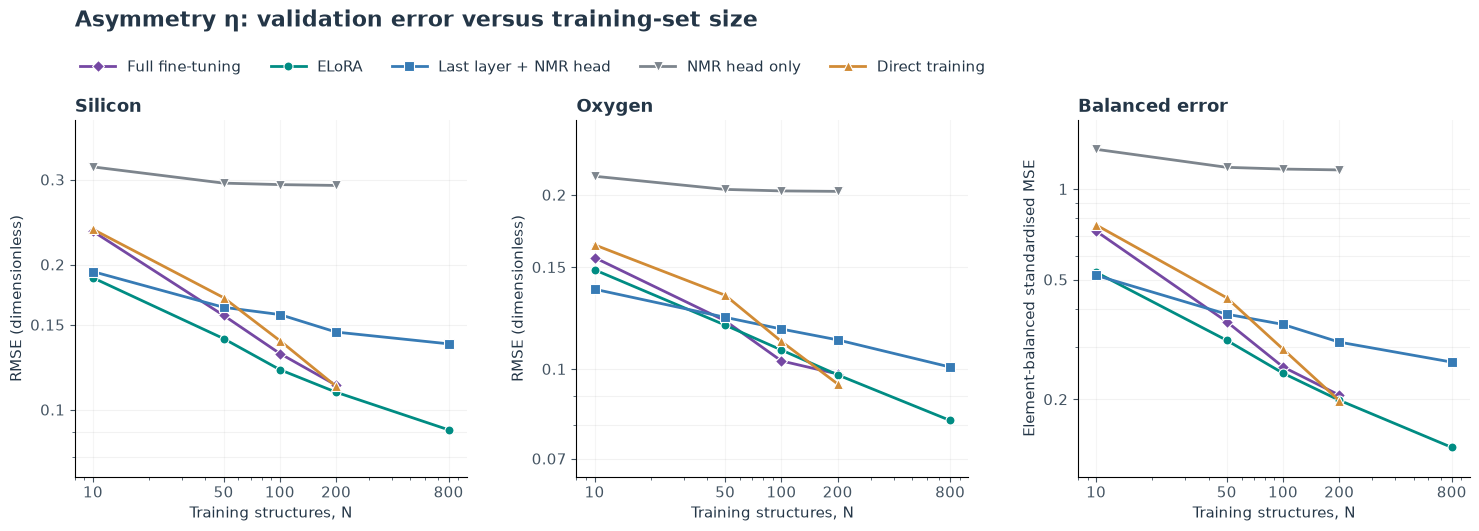

In [6]:
for q in ['isotropy', 'anisotropy', 'asymmetry']:
    fig = plot_parameter_curves(curves, q, 'validation')
    save_figure(fig, FIGURES, f'validation-{q}-learning-curves')
    plt.show()

## Interpretation

Single-seed results on the 150-structure test set. N800 is available only for ELoRA and last layer + NMR head.

- **Pretraining helps most when labelled data are scarce.** At N10, ELoRA's balanced isotropy error is 0.049, compared with 0.117 for direct training. Direct training closes most of the gap by N200: Si σiso is 0.98 ppm against 0.83 ppm for ELoRA, and the anisotropy and asymmetry scores are similar.
- **ELoRA is the best or close to the best at every N.** It has the lowest balanced error for all three parameters from N50 upwards, apart from asymmetry at N100, where full fine-tuning is marginally better (0.208 against 0.218). At N800 it reaches Si/O σiso RMSE of 0.66/1.68 ppm.
- **Full fine-tuning starts worse than ELoRA but catches up.** It is worse at N10 (balanced isotropy 0.080 against 0.049) and reaches similar errors by N100–200.
- **Last layer + NMR head does best at N10 for anisotropy and asymmetry, then levels off.** By N200 it is the weakest of the trainable-backbone methods for all three parameters.
- **NMR head only plateaus by N50.** Its anisotropy RMSE barely changes after that (Si about 37 ppm). Its balanced asymmetry error is about 1.1, slightly worse than predicting the training-pool mean η for every atom. With the backbone frozen, the E/F features alone do not carry enough information about the shielding tensor's shape.
- **Anisotropy and asymmetry are much harder than isotropy for every method.** The best balanced errors are about 0.16 and 0.11, compared with 0.007 for isotropy. The headline errors include opposite-sign anisotropy cases.

The direct training, full fine-tuning and NMR-head-only N800 runs reached the 12-hour limit and are not plotted. These are single-seed curves, so small differences between methods, particularly at N100–200, are within plausible seed-to-seed variation.
